In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

In [39]:
cols = ["mpg", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "car_name"]
df_raw = pd.read_csv("auto-mpg.data", sep=r"\s+", names=cols, na_values="?", quotechar='"')
df_raw.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [40]:
print("First 5 rows:")
display(df_raw.head())
print("Last 5 rows:")
display(df_raw.tail())

First 5 rows:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


Last 5 rows:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.0,2720.0,19.4,82,1,chevy s-10


In [41]:
print("Rows, columns:", df_raw.shape)

Rows, columns: (398, 9)


In [42]:
print("Column names:", list(df_raw.columns))

Column names: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']


In [43]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB


In [44]:
numerical_cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
categorical_cols = ["origin", "car_name"]
print("Numerical columns  :", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns  : ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Categorical columns: ['origin', 'car_name']


In [45]:
df_raw[numerical_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0


In [46]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2)
})
missing

,missing_count,missing_percent
mpg,0,0.00
cylinders,0,0.00
displacement,0,0.00
horsepower,6,1.51
weight,0,0.00
acceleration,0,0.00
model_year,0,0.00
origin,0,0.00
car_name,0,0.00


In [47]:
print("Columns with no missing values:", list(missing.index[missing.missing_count == 0]))
print("Columns needing attention     :", list(missing.index[missing.missing_count > 0]))
print()
print("Rows with a missing value:")
display(df_raw[df_raw.isna().any(axis=1)])

Columns with no missing values: ['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']
Columns needing attention     : ['horsepower']

Rows with a missing value:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


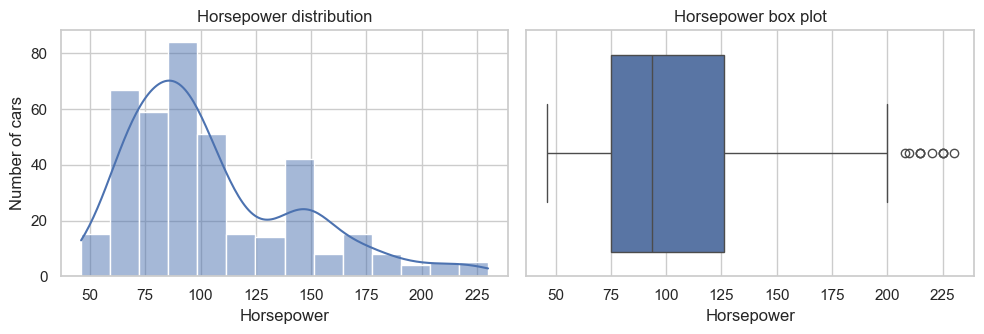

In [48]:
df = df_raw.copy()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df["horsepower"].dropna(), kde=True, ax=ax[0])
ax[0].set_title("Horsepower distribution")
ax[0].set_xlabel("Horsepower")
ax[0].set_ylabel("Number of cars")
sns.boxplot(x=df["horsepower"], ax=ax[1])
ax[1].set_title("Horsepower box plot")
ax[1].set_xlabel("Horsepower")
plt.tight_layout()
plt.show()

In [49]:
print("Mean   :", round(df["horsepower"].mean(), 2))
print("Median :", df["horsepower"].median())
print("Skew   :", round(df["horsepower"].skew(), 2))

Mean   : 104.47
Median : 93.5
Skew   : 1.09


In [50]:
median_hp = df["horsepower"].median()
df["horsepower"] = df["horsepower"].fillna(median_hp)

print("Median used for filling:", median_hp)
print()
print("Missing values after handling:")
print(df.isna().sum())

Median used for filling: 93.5

Missing values after handling:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


In [51]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicates ignoring car_name:", df.drop(columns="car_name").duplicated().sum())

Fully duplicated rows: 0
Duplicates ignoring car_name: 0


In [52]:
df["brand"] = df["car_name"].str.strip().str.lower().str.split().str[0]
print(sorted(df["brand"].unique()))

['amc', 'audi', 'bmw', 'buick', 'cadillac', 'capri', 'chevroelt', 'chevrolet', 'chevy', 'chrysler', 'datsun', 'dodge', 'fiat', 'ford', 'hi', 'honda', 'maxda', 'mazda', 'mercedes', 'mercedes-benz', 'mercury', 'nissan', 'oldsmobile', 'opel', 'peugeot', 'plymouth', 'pontiac', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'triumph', 'vokswagen', 'volkswagen', 'volvo', 'vw']


In [53]:
brand_fix = {
    "chevroelt": "chevrolet", "chevy": "chevrolet",
    "toyouta": "toyota",
    "maxda": "mazda",
    "vokswagen": "volkswagen", "vw": "volkswagen",
    "mercedes": "mercedes-benz",
}
before = df["brand"].nunique()
df["brand"] = df["brand"].replace(brand_fix)
after = df["brand"].nunique()
print(f"Distinct brands before: {before}, after: {after}")
print()
print(df["brand"].value_counts().head(10))

Distinct brands before: 37, after: 30

brand
ford          51
chevrolet     47
plymouth      31
amc           28
dodge         28
toyota        26
datsun        23
volkswagen    22
buick         17
pontiac       16
Name: count, dtype: int64


In [54]:
# Map the coded origin values to readable labels (from the dataset documentation)
origin_map = {1: "USA", 2: "Europe", 3: "Japan"}
df["origin"] = df["origin"].map(origin_map)

# Model year is stored as two digits (70 = 1970), so make it a full year
df["model_year"] = df["model_year"] + 1900

print(df["origin"].value_counts())
print()
print(sorted(df["model_year"].unique()))

origin
USA       249
Japan      79
Europe     70
Name: count, dtype: int64

[np.int64(1970), np.int64(1971), np.int64(1972), np.int64(1973), np.int64(1974), np.int64(1975), np.int64(1976), np.int64(1977), np.int64(1978), np.int64(1979), np.int64(1980), np.int64(1981), np.int64(1982)]


In [55]:
num_features = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
df[num_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,398.0,104.30,38.22,46.0,76.00,93.5,125.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,1976.01,3.70,1970.0,1973.00,1976.0,1979.00,1982.0


In [56]:
print("Cars by origin:")
display(df["origin"].value_counts().to_frame("count").assign(percent=lambda t: (t["count"] / t["count"].sum() * 100).round(1)))
print("Cars by number of cylinders:")
display(df["cylinders"].value_counts().sort_index().to_frame("count"))

Cars by origin:


,count,percent
origin,,
USA,249,62.6
Japan,79,19.8
Europe,70,17.6


Cars by number of cylinders:


,count
cylinders,
3,4
4,204
5,3
6,84
8,103


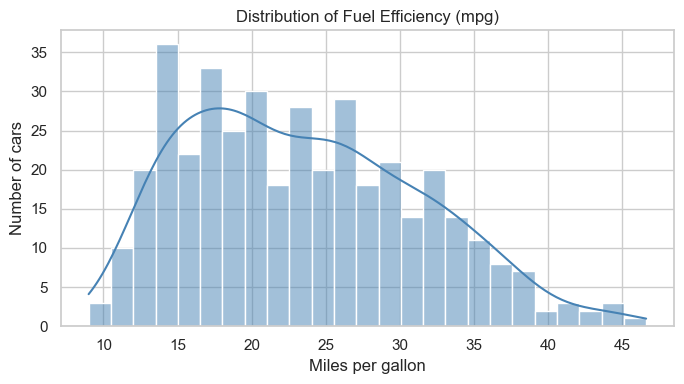

In [57]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["mpg"], bins=25, kde=True, ax=ax, color="steelblue")
ax.set_title("Distribution of Fuel Efficiency (mpg)")
ax.set_xlabel("Miles per gallon")
ax.set_ylabel("Number of cars")
plt.tight_layout()
plt.show()

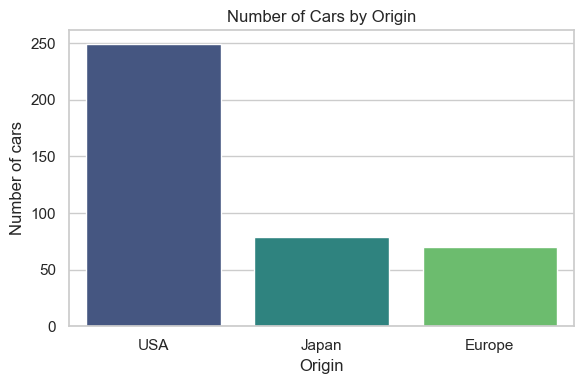

In [58]:
fig, ax = plt.subplots(figsize=(6, 4))
order = df["origin"].value_counts().index
sns.countplot(data=df, x="origin", order=order, ax=ax, palette="viridis", hue="origin", legend=False)
ax.set_title("Number of Cars by Origin")
ax.set_xlabel("Origin")
ax.set_ylabel("Number of cars")
plt.tight_layout()
plt.show()

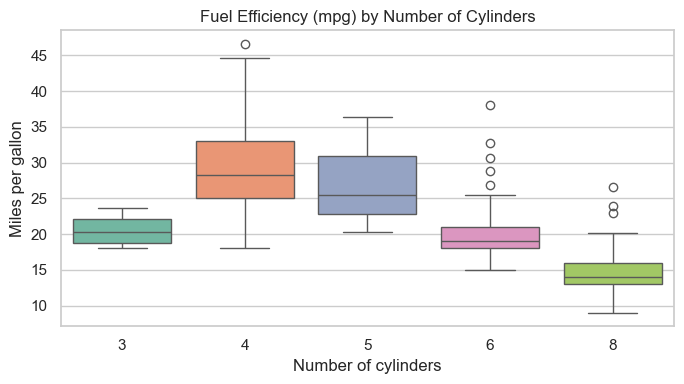

In [59]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="cylinders", y="mpg", ax=ax, palette="Set2", hue="cylinders", legend=False)
ax.set_title("Fuel Efficiency (mpg) by Number of Cylinders")
ax.set_xlabel("Number of cylinders")
ax.set_ylabel("Miles per gallon")
plt.tight_layout()
plt.show()

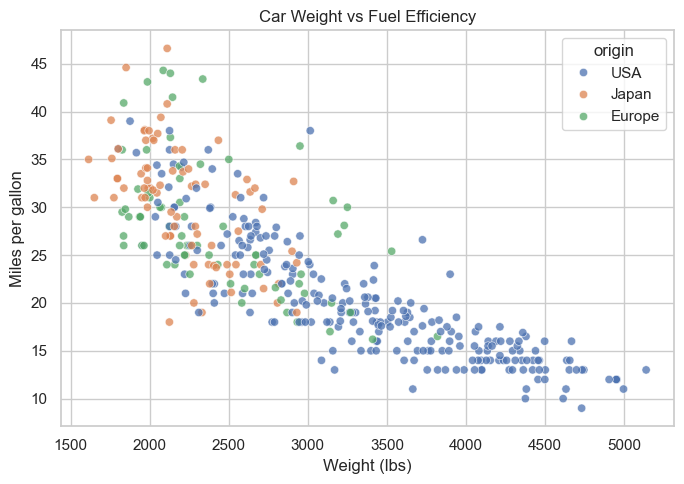

In [60]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="weight", y="mpg", hue="origin", alpha=0.75, ax=ax)
ax.set_title("Car Weight vs Fuel Efficiency")
ax.set_xlabel("Weight (lbs)")
ax.set_ylabel("Miles per gallon")
plt.tight_layout()
plt.show()

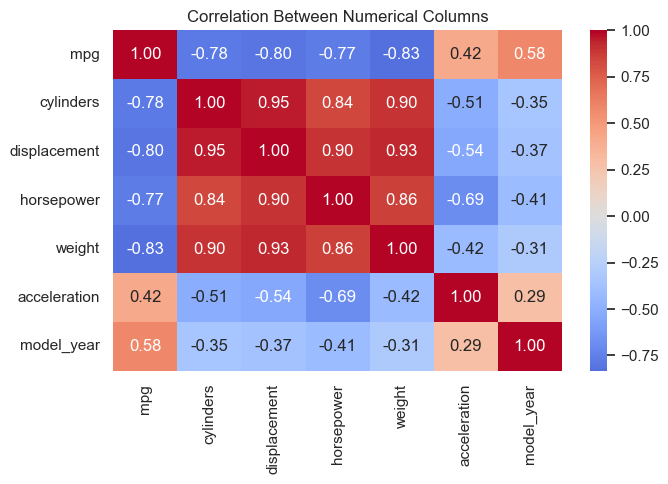

Correlation of each column with mpg:
weight         -0.83
displacement   -0.80
cylinders      -0.78
horsepower     -0.77
acceleration    0.42
model_year      0.58
Name: mpg, dtype: float64


In [61]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[num_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Numerical Columns")
plt.tight_layout()
plt.show()

print("Correlation of each column with mpg:")
print(df[num_features].corr()["mpg"].drop("mpg").sort_values().round(2))

In [62]:
print("Average mpg by origin:")
print(df.groupby("origin")["mpg"].mean().round(2).sort_values(ascending=False))

Average mpg by origin:
origin
Japan     30.45
Europe    27.89
USA       20.08
Name: mpg, dtype: float64


In [63]:
print("Before encoding:")
display(df[["origin"]].head())

Before encoding:


,origin
0,USA
1,USA
2,USA
3,USA
4,USA


In [64]:
# origin is nominal (no natural order between USA, Europe and Japan), so one-hot encoding is used.
origin_dummies = pd.get_dummies(df["origin"], prefix="origin", dtype=int)
print("After encoding:")
display(origin_dummies.head())
print("Columns created:", list(origin_dummies.columns))

After encoding:


,origin_Europe,origin_Japan,origin_USA
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1


Columns created: ['origin_Europe', 'origin_Japan', 'origin_USA']


In [65]:
feature_cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
print(df[feature_cols].agg(["min", "max"]).T)

                 min     max
cylinders        3.0     8.0
displacement    68.0   455.0
horsepower      46.0   230.0
weight        1613.0  5140.0
acceleration     8.0    24.8
model_year    1970.0  1982.0


In [66]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(df[feature_cols]), columns=feature_cols, index=df.index)

print("Mean after scaling (should be ~0):")
print(scaled.mean().round(3))
print()
print("Std after scaling (should be ~1):")
print(scaled.std(ddof=0).round(3))

Mean after scaling (should be ~0):
cylinders      -0.0
displacement   -0.0
horsepower     -0.0
weight         -0.0
acceleration   -0.0
model_year      0.0
dtype: float64

Std after scaling (should be ~1):
cylinders       1.0
displacement    1.0
horsepower      1.0
weight          1.0
acceleration    1.0
model_year      1.0
dtype: float64


In [67]:
# 1) Cleaned dataset (readable, not scaled or encoded) - useful for reference and further EDA
cleaned = df[["mpg", "cylinders", "displacement", "horsepower", "weight",
              "acceleration", "model_year", "origin", "brand", "car_name"]]
cleaned.to_csv("auto_mpg_cleaned.csv", index=False)

# 2) Prepared dataset (target + scaled numeric features + one-hot origin) - ready for ML
prepared = pd.concat([df[["mpg"]], scaled, origin_dummies], axis=1)
prepared.to_csv("auto_mpg_prepared.csv", index=False)

print("Cleaned  file shape :", cleaned.shape)
print("Prepared file shape :", prepared.shape)

Cleaned  file shape : (398, 10)
Prepared file shape : (398, 10)


In [68]:
final = pd.read_csv("auto_mpg_prepared.csv")
print("Final shape:", final.shape)
print("Remaining missing values:", int(final.isna().sum().sum()))
print("Duplicate rows         :", int(final.duplicated().sum()))
print()
print("Final file name: auto_mpg_prepared.csv")
final.head(10).round(3)

Final shape: (398, 10)
Remaining missing values: 0
Duplicate rows         : 0

Final file name: auto_mpg_prepared.csv


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_Europe,origin_Japan,origin_USA
0,18.0,1.498,1.091,0.673,0.631,-1.295,-1.627,0,0,1
1,15.0,1.498,1.504,1.590,0.854,-1.477,-1.627,0,0,1
2,18.0,1.498,1.196,1.197,0.550,-1.659,-1.627,0,0,1
3,16.0,1.498,1.062,1.197,0.547,-1.295,-1.627,0,0,1
4,17.0,1.498,1.043,0.935,0.566,-1.840,-1.627,0,0,1
5,15.0,1.498,2.262,2.454,1.620,-2.022,-1.627,0,0,1
6,14.0,1.498,2.502,3.031,1.636,-2.385,-1.627,0,0,1
7,14.0,1.498,2.368,2.900,1.586,-2.566,-1.627,0,0,1
8,14.0,1.498,2.512,3.162,1.720,-2.022,-1.627,0,0,1
9,15.0,1.498,1.888,2.245,1.040,-2.566,-1.627,0,0,1


In [69]:
# Confirm the original file was not changed
orig_check = pd.read_csv("auto-mpg.data", sep=r"\s+", names=cols, na_values="?", quotechar='"')
print("Original file unchanged:", orig_check.equals(df_raw))

Original file unchanged: True
